In [43]:
import numpy as np 
#from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, ConfusionMatrixDisplay
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
#from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,f1_score, precision_score, roc_auc_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd
#from sklearn.svm import SVR
#import time
#import seaborn as sns
from joblib import Parallel, delayed
from pathlib import Path
import os

plt.rcParams['font.size'] = 14
RISK_LABELS = ["safe", "low", "moderate", "high"]

In [44]:
data_dir = Path("data")

X_loaded = pd.read_csv(data_dir / "processed_data.csv", index_col=0)
y_loaded = pd.read_csv(data_dir / "processed_target.csv", index_col=0).squeeze("columns")

print(f"Loaded x shape: {X_loaded.shape}\nLoaded y shape: {y_loaded.shape}")
assert X_loaded.index.equals(y_loaded.index)

Loaded x shape: (4955, 15)
Loaded y shape: (4955,)


In [45]:
#scaling
scaler = StandardScaler()
scaler.fit(X_loaded)
X_scaled = scaler.transform(X_loaded)

In [46]:
#create target vector
y = y_loaded

In [47]:
#train validation test Split
Test_ratio = 0.25
Shuffle_state = 4720
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled,y,test_size=Test_ratio,random_state=Shuffle_state)
X_test, X_val, y_test, y_val = train_test_split(X_temp,y_temp,test_size=0.5,random_state=Shuffle_state)

In [48]:
#target scaling
u = np.mean(y_train)
s = np.std(y_train)
y_train_s = (y_train-u)/s
y_test_s = (y_test-u)/s
y_val_s = (y_val-u)/s

In [79]:
#train best factor model
best_mlp_model = MLPRegressor(
    hidden_layer_sizes=(200, 200, 200, 200, 200, 200, 200, 200, 200, 200),
    activation='relu',
    solver='adam',
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    shuffle=True,
    random_state=42
    )
best_mlp_model.fit(X_train,np.ravel(y_train_s))


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(200, ...)"
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.01
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",20
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to de

# Risk state estimation
In this Task a model is developed to estimate the Risk state of a new unseen sample. 


The first way to get the Risk state is by of one of the regression models, predicting the value and then sort it into the according classes

In [49]:
thresholds = [0.1, 0.35, 0.7, 1]

In [50]:
def plot_confusion(conf, name):
    """
    Plot and save the confusion matrix returned by analyze_results.
    The diagonal is shown in white and does not affect the colour scale,
    so the off-diagonal (error) cells stay readable.
    conf:      confusion matrix (4x4 array)
    name:      used for the title and the filename (saved as figures/q4/<name>.png)
    normalize: None (counts), "true" (rows sum to 1), "pred", or "all"
    """
    conf = np.asarray(conf, dtype=float)

    n = conf.shape[0]
    diag = np.eye(n, dtype=bool)

    # colour scale is set by the off-diagonal cells only
    vmax = conf[~diag].max() if n > 1 else 1.0
    if vmax <= 0:
        vmax = 1.0

    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("white")                       # masked (diagonal) cells -> white
    masked = np.ma.masked_array(conf, mask=diag)

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(masked, cmap=cmap, vmin=0, vmax=vmax)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # numbers in every cell, including the diagonal
    fmt = ".0f"
    for i in range(n):
        for j in range(n):
            if i == j:
                color = "black"
            else:
                color = "white" if conf[i, j] > 0.5 * vmax else "black"
            ax.text(j, i, format(conf[i, j], fmt),
                    ha="center", va="center", color=color)

    labels = RISK_LABELS[:n]
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted risk state")
    ax.set_ylabel("True risk state")
    ax.set_title(f"Confusion matrix: {name}")
    fig.tight_layout()

    os.makedirs("figures/q4", exist_ok=True)
    fig.savefig(f"figures/q4/{name}.png", dpi=200)
    plt.show()
    plt.close(fig)

In [51]:
def sort_in_class(y, thresholds):
    y = np.asarray(y)  # Convert to NumPy array

    y_class = []
    for i in range(len(y)):
        for j in range(len(thresholds)):
            if y[i] < thresholds[j] or thresholds[j] >= 1:
                y_class.append(j)
                break
        else:
            y_class.append(len(thresholds))

    return np.array(y_class)

y_class_train = sort_in_class(y_train, thresholds)
y_class_val = sort_in_class(y_val, thresholds)
y_class_test = sort_in_class(y_train, thresholds)
                  

Just quick overview over class sizes:

[[163   0   0   0]
 [  0 220   0   0]
 [  0   0 129   0]
 [  0   0   0 108]]


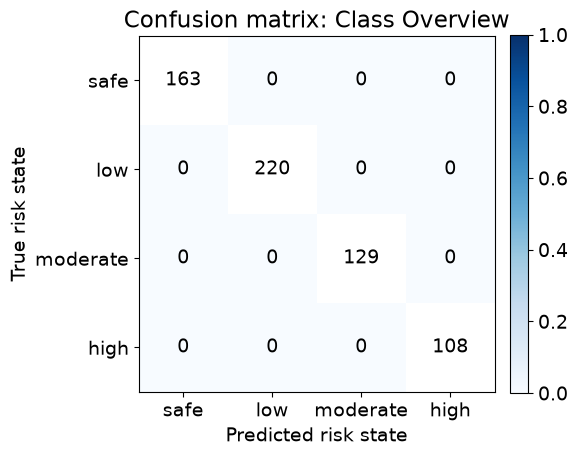

In [52]:
print(confusion_matrix(y_class_val, y_class_val))
plot_confusion(confusion_matrix(y_class_val, y_class_val), "Class Overview")

In [53]:
def estimate_class_with_regression(model, x, thresholds):
    y = model.predict(x)*s+u
    print(np.shape(x))
    y_class = sort_in_class(y, thresholds)
    return y_class

y_class_predicted = estimate_class_with_regression(best_mlp_model, X_val, thresholds)
np.shape(y_class_predicted)

(620, 15)


(620,)

Function to analyse reults

Problem: In this application it is way more dangerous to classify something too low compared to classifing it too high. Therefore i introduce a new metric. This is why a new metric is intruduced. It looks, where the classification was too low and then multiplies this mistake with a weight. If it classfies too high, it is just linear. Therefore in this classifier a lower value is better.

In [110]:
def custum_metric(y_class_true, y_class_predicted, factor):
    errors = np.asarray(y_class_true) - np.asarray(y_class_predicted)
    weights = np.where(errors > 0, factor, 1)
    
    return np.mean(weights * errors**2)

In [86]:
def analyze_results(y_class_test, y_class_pred):
    custum = custum_metric(y_class_test, y_class_pred, 3)
    return (
        accuracy_score(y_class_test,y_class_pred), 
        precision_score(y_class_test,y_class_pred,average='macro'), 
        recall_score(y_class_test,y_class_pred, average='macro'), 
        f1_score(y_class_test, y_class_pred, average='macro'), 
        confusion_matrix(y_class_test, y_class_pred),
        custum
        )
        

In [87]:
def Classifier(model, x_train, y_class_train, x_val, y_class_val):
    model = model.fit(x_train, y_class_train)
    y_class_pred = model.predict(x_val)
    return analyze_results(y_class_val, y_class_pred)
    

In [88]:
analyze_results(y_class_val, y_class_predicted)

(0.9274193548387096,
 0.9212293554398817,
 0.9357156959810691,
 0.926955787504641,
 array([[161,   2,   0,   0],
        [ 10, 191,  19,   0],
        [  0,   2, 118,   9],
        [  0,   0,   3, 105]]),
 np.float64(0.12096774193548387))

Next is the kNN classifier:

In [89]:
n_neighbors = [3, 5, 8, 12]
res_knn = []
for i in n_neighbors:
    knn = KNeighborsClassifier(n_neighbors=i)
    res_knn.append(Classifier(knn, X_train, y_class_train, X_val, y_class_val))

In [ ]:
# Extract metrics
acc    = np.array([r[0] for r in res_knn])
prec   = np.array([r[1] for r in res_knn])
recall = np.array([r[2] for r in res_knn])
f1     = np.array([r[3] for r in res_knn])
conf   = [r[4] for r in res_knn]
custum = np.array([r[5] for r in res_knn])

# Find best number of neighbors based on custom metric (lower is better)
best_idx = np.argmin(custum)

print("Model: kNN")
print("Number of combinations:", len(n_neighbors))
print("Best custom metric value:", custum[best_idx])
print("Best number of neighbors:", n_neighbors[best_idx])
print("Accuracy at best k:", acc[best_idx])
print("F1 at best k:", f1[best_idx])
print("Best confusion matrix:")
print(conf[best_idx])

plot_confusion(conf[best_idx], "KNC")

Model: kNN
Number of combinations: 4
Best custom metric value: 0.9096774193548387
Best number of neighbors: 5
Accuracy at best k: 0.6951612903225807
F1 at best k: 0.6817521460890651
Best confusion matrix:
[[138  25   0   0]
 [ 38 168  13   1]
 [  4  58  58   9]
 [  0   6  35  67]]


In [91]:
print(custum)

[1.07903226 0.90967742 1.05322581 0.95806452]


In [92]:
#SVC linear


svm_C = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]

def test_parameters_linear(C_var):
    model = SVC(
        kernel="linear",
        max_iter=5_000_000,
        C=C_var
    )

    model.fit(X_train, y_class_train)

    acc, prec, recall, f1, conf, custum= analyze_results(
        y_class_val, model.predict(X_val)
    )

    return C_var, acc, prec, recall, f1, conf, custum, model.fit_status_


results_linear = Parallel(n_jobs=-2)(
    delayed(test_parameters_linear)(C)
    for C in svm_C
)

In [93]:
C_values = np.array([r[0] for r in results_linear])
acc      = np.array([r[1] for r in results_linear])
prec     = np.array([r[2] for r in results_linear])
recall   = np.array([r[3] for r in results_linear])
f1       = np.array([r[4] for r in results_linear])
conf     = [r[5] for r in results_linear]
custum   = np.array([r[6] for r in results_linear])
status   = np.array([r[7] for r in results_linear])

# Find best C based on custom metric (lower is better)
valid = np.where(status == 0)[0]
best_idx = valid[np.argmin(custum[valid])]

print("Kernel: linear")
print("Number of combinations:", len(C_values))
print("Best custom metric value:", custum[best_idx])
print("Best C:", C_values[best_idx])
print("Accuracy at best C:", acc[best_idx])

Kernel: linear
Number of combinations: 8
Best custom metric value: 1.032258064516129
Best C: 0.5
Accuracy at best C: 0.6709677419354839


In [94]:
# SVC RBF

svm_C = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_gamma = [0.001, 0.01, 0.1, 1, 10, "scale"]

def test_parameters_rbf(C_var, gamma_var):
    model = SVC(
        kernel="rbf",
        max_iter=5_000_000,
        C=C_var,
        gamma=gamma_var
    )

    model.fit(X_train, y_class_train)

    acc, prec, recall, f1, conf, custum = analyze_results(
        y_class_val, model.predict(X_val)
    )

    return C_var, gamma_var, acc, prec, recall, f1, conf, custum, model.fit_status_


results_rbf = Parallel(n_jobs=-2)(
    delayed(test_parameters_rbf)(C, gamma)
    for C in svm_C
    for gamma in svm_gamma
)

/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

In [ ]:
C_values     = np.array([r[0] for r in results_rbf])
gamma_values = np.array([r[1] for r in results_rbf])

acc    = np.array([r[2] for r in results_rbf])
prec   = np.array([r[3] for r in results_rbf])
recall = np.array([r[4] for r in results_rbf])
f1     = np.array([r[5] for r in results_rbf])
conf   = np.array([r[6] for r in results_rbf])
custum = np.array([r[7] for r in results_rbf])
status = np.array([r[8] for r in results_rbf])

# Find best combination based on custom metric
valid = np.where(status == 0)[0]
best_idx = valid[np.argmin(custum[valid])]

print("Kernel: rbf")
print("Number of combinations:", np.size(acc))
print("Best custum metric value:", custum[best_idx])
print("Best C:", C_values[best_idx])
print("Best gamma:", gamma_values[best_idx])
print("Best accuracy:", acc[best_idx])
print("Best Confusion matrix:")
print(conf[best_idx])

plot_confusion(conf[best_idx], "RBF SVC")

Kernel: rbf
Number of combinations: 48
Best custum metric value: 0.2467741935483871
Best C: 100.0
Best gamma: 0.01
Best accuracy: 0.8790322580645161
Best Confusion matrix:
[[150  13   0   0]
 [ 15 193  12   0]
 [  0  14 104  11]
 [  0   0  10  98]]


In [96]:
# SVC Sigmoid

svm_C = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_gamma = [0.001, 0.01, 0.1, 1, 10, "scale"]
svm_coef0 = [-2, -1, 0, 1, 2]

def test_parameters_sigmoid(C_var, gamma_var, coef0_var):
    model = SVC(
        kernel="sigmoid",
        max_iter=5_000_000,
        C=C_var,
        gamma=gamma_var,
        coef0=coef0_var
    )

    model.fit(X_train, y_class_train)

    acc, prec, recall, f1, conf, custum = analyze_results(
        y_class_val, model.predict(X_val)
    )

    return C_var, gamma_var, coef0_var, acc, prec, recall, f1, conf, custum, model.fit_status_


results_sigmoid = Parallel(n_jobs=-2)(
    delayed(test_parameters_sigmoid)(C, gamma, coef0)
    for C in svm_C
    for gamma in svm_gamma
    for coef0 in svm_coef0
)

/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

Kernel: sigmoid
Number of combinations: 240
Best custom metric value: 0.47580645161290325
Best C: 100.0
Best gamma: 0.01
Best coef0: -1
Best accuracy: 0.8032258064516129
Best Confusion matrix:
[[141  19   0   3]
 [ 21 182  12   5]
 [  0  18  95  16]
 [  0   0  28  80]]


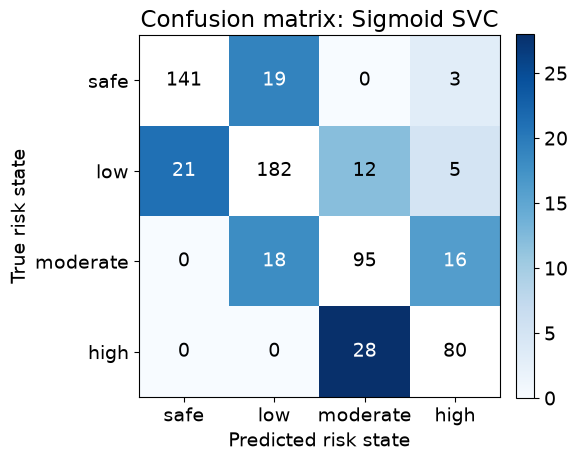

In [121]:
C_values     = np.array([r[0] for r in results_sigmoid])
gamma_values = np.array([r[1] for r in results_sigmoid])
coef0_values = np.array([r[2] for r in results_sigmoid])

acc    = np.array([r[3] for r in results_sigmoid])
prec   = np.array([r[4] for r in results_sigmoid])
recall = np.array([r[5] for r in results_sigmoid])
f1     = np.array([r[6] for r in results_sigmoid])
conf   = [r[7] for r in results_sigmoid]
custum = np.array([r[8] for r in results_sigmoid])
status = np.array([r[9] for r in results_sigmoid])

# Find best combination based on custom metric
valid = np.where((status == 0) & np.isfinite(custum))[0]

if len(valid) == 0:
    print("No converged models with a finite custom metric.")
else:
    best_idx = valid[np.argmin(custum[valid])]

    print("Kernel: sigmoid")
    print("Number of combinations:", np.size(acc))
    print("Best custom metric value:", custum[best_idx])
    print("Best C:", C_values[best_idx])
    print("Best gamma:", gamma_values[best_idx])
    print("Best coef0:", coef0_values[best_idx])
    print("Best accuracy:", acc[best_idx])
    print("Best Confusion matrix:")
    print(conf[best_idx])

plot_confusion(conf[best_idx], "Sigmoid SVC")

In [119]:
# SVC Polynomial

svm_C = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_gamma = ["scale", "auto", 0.001, 0.01, 0.1, 1]
svm_degree = [2, 3]
svm_coef0 = [-1, 0, 1, 2]

def test_parameters_poly(C_var, gamma_var, degree_var, coef0_var):
    model = SVC(
        kernel="poly",
        max_iter=5_000_000,
        C=C_var,
        gamma=gamma_var,
        degree=degree_var,
        coef0=coef0_var
    )

    model.fit(X_train, y_class_train)

    acc, prec, recall, f1, conf, custum = analyze_results(
        y_class_val, model.predict(X_val)
    )

    return C_var, gamma_var, degree_var, coef0_var, acc, prec, recall, f1, conf, custum, model.fit_status_


results_poly = Parallel(n_jobs=-2)(
    delayed(test_parameters_poly)(C, gamma, degree, coef0)
    for C in svm_C
    for gamma in svm_gamma
    for degree in svm_degree
    for coef0 in svm_coef0
)

/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hremmen/Documents/ML4EE/ML4EE_project/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

Kernel: polynomial
Number of combinations: 384
Best custom metric value: 0.2064516129032258
Best C: 10.0
Best gamma: scale
Best degree: 3
Best coef0: 2
Best accuracy: 0.9032258064516129
Best F1: 0.9017697623773487
Converged: True
Best confusion matrix:
[[154   9   0   0]
 [ 14 200   6   0]
 [  0  15 103  11]
 [  0   0   5 103]]


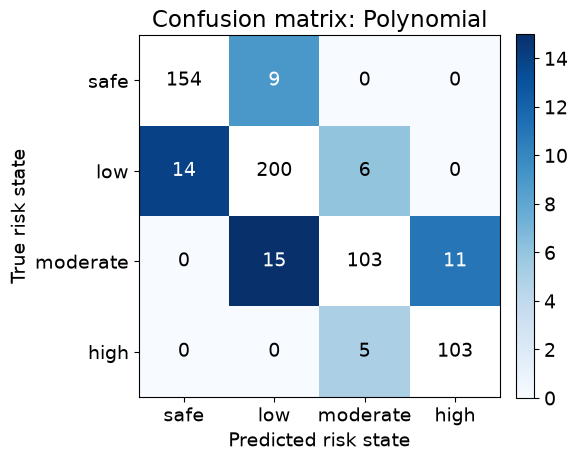

In [120]:
C_values      = np.array([r[0] for r in results_poly])
gamma_values  = np.array([r[1] for r in results_poly])
degree_values = np.array([r[2] for r in results_poly])
coef0_values  = np.array([r[3] for r in results_poly])

acc    = np.array([r[4] for r in results_poly])
prec   = np.array([r[5] for r in results_poly])
recall = np.array([r[6] for r in results_poly])
f1     = np.array([r[7] for r in results_poly])
conf   = [r[8] for r in results_poly]
custum = np.array([r[9] for r in results_poly])
status = np.array([r[10] for r in results_poly])

# Find best combination based on custom metric (lower is better)
valid = np.where((status == 0) & np.isfinite(custum))[0]

if len(valid) == 0:
    print("No converged models with a finite custom metric.")
else:
    best_idx = valid[np.argmin(custum[valid])]

    print("Kernel: polynomial")
    print("Number of combinations:", np.size(acc))
    print("Best custom metric value:", custum[best_idx])
    print("Best C:", C_values[best_idx])
    print("Best gamma:", gamma_values[best_idx])
    print("Best degree:", degree_values[best_idx])
    print("Best coef0:", coef0_values[best_idx])
    print("Best accuracy:", acc[best_idx])
    print("Best F1:", f1[best_idx])
    print("Converged:", status[best_idx] == 0)
    print("Best confusion matrix:")
    print(conf[best_idx])

plot_confusion(conf[best_idx], "Polynomial")

In [100]:
# Decision Tree Classifier

tree_depth = [3, 5, 8, 12, 16, None]
tree_min_split = [2, 5, 10, 20]
tree_min_leaf = [1, 2, 5, 10]
tree_alpha = [0.0, 0.0001, 0.001, 0.01]


def test_parameters_tree(depth_var, split_var, leaf_var, alpha_var):

    model = DecisionTreeClassifier(
        max_depth=depth_var,
        min_samples_split=split_var,
        min_samples_leaf=leaf_var,
        ccp_alpha=alpha_var,
        random_state=42
    )

    model.fit(X_train, y_class_train)

    acc, prec, recall, f1, conf, custum = analyze_results(
        y_class_val, model.predict(X_val)
    )

    return depth_var, split_var, leaf_var, alpha_var, acc, prec, recall, f1, conf, custum


results_tree = Parallel(n_jobs=-2)(
    delayed(test_parameters_tree)(depth, split, leaf, alpha)
    for depth in tree_depth
    for split in tree_min_split
    for leaf in tree_min_leaf
    for alpha in tree_alpha
)

Model: Decision Tree
Number of combinations: 384
Best custom metric value: 0.65
Best max_depth: 12
Best min_samples_split: 2
Best min_samples_leaf: 1
Best ccp_alpha: 0.0
Best accuracy: 0.6951612903225807
Best F1: 0.6919209337300715
Best confusion matrix:
[[123  37   3   0]
 [ 22 158  38   2]
 [  1  30  75  23]
 [  0   2  31  75]]


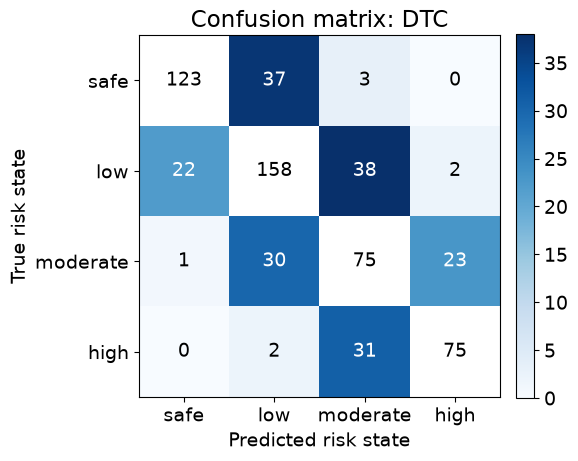

In [118]:
depth_values = [r[0] for r in results_tree]
split_values = np.array([r[1] for r in results_tree])
leaf_values  = np.array([r[2] for r in results_tree])
alpha_values = np.array([r[3] for r in results_tree])

acc    = np.array([r[4] for r in results_tree])
prec   = np.array([r[5] for r in results_tree])
recall = np.array([r[6] for r in results_tree])
f1     = np.array([r[7] for r in results_tree])
conf   = [r[8] for r in results_tree]
custum = np.array([r[9] for r in results_tree])

# Find best combination based on custom metric (lower is better)
best_idx = np.argmin(custum)

print("Model: Decision Tree")
print("Number of combinations:", len(acc))
print("Best custom metric value:", custum[best_idx])
print("Best max_depth:", depth_values[best_idx])
print("Best min_samples_split:", split_values[best_idx])
print("Best min_samples_leaf:", leaf_values[best_idx])
print("Best ccp_alpha:", alpha_values[best_idx])
print("Best accuracy:", acc[best_idx])
print("Best F1:", f1[best_idx])
print("Best confusion matrix:")
print(conf[best_idx])

plot_confusion(conf[best_idx], "DTC")

In [54]:
# MLP Classifier

mlp_layers = [
    #(50,),                  # 1 layer, 50 neurons
    #(100,),                 # 1 layer, 100 neurons
    #(150,),
    #(200,),
    #(250,),
    (300,),
    (350,),
    (400,),
    (600,),
    (800,)
]

mlp_alpha = [0.0001, 0.001, 0.01, 0.1]
mlp_lr = [0.0001, 0.001, 0.01]
mlp_activation = ["relu", "tanh"]
mlp_batch = [64, 256]


def test_parameters_mlp(hidden_var, alpha_var, lr_var, activation_var, batch_var):

    model = MLPClassifier(
        hidden_layer_sizes=hidden_var,  # FIXED
        alpha=alpha_var,
        learning_rate_init=lr_var,
        activation=activation_var,
        batch_size=batch_var,
        solver="adam",
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=42
    )

    model.fit(X_train, y_class_train)

    acc, prec, recall, f1, conf, custum = analyze_results(
        y_class_val, model.predict(X_val)
    )

    return (
        hidden_var,
        alpha_var,
        lr_var,
        activation_var,
        batch_var,
        acc,
        prec,
        recall,
        f1,
        conf,
        custum,
        model.n_iter_
    )


results_mlp = Parallel(n_jobs=-2)(
    delayed(test_parameters_mlp)(hidden, alpha, lr, activation, batch)
    for hidden in mlp_layers
    for alpha in mlp_alpha
    for lr in mlp_lr
    for activation in mlp_activation
    for batch in mlp_batch
)

Model: MLP Classifier
Number of combinations: 240
Best custom metric value: 0.12419354838709677
Best hidden_layer_sizes: (350,)
Best alpha: 0.01
Best learning_rate_init: 0.01
Best activation: relu
Best batch_size: 64
Best accuracy: 0.9209677419354839
Best F1: 0.9190005466619496
Training iterations: 44
Best confusion matrix:
[[146  17   0   0]
 [  1 210   9   0]
 [  0   6 114   9]
 [  0   0   7 101]]


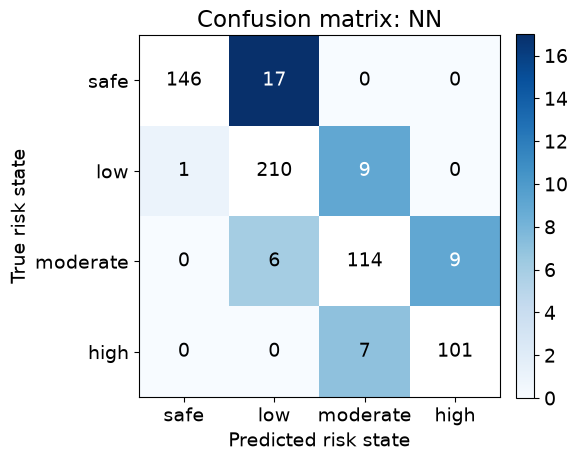

In [55]:
hidden_values     = [r[0] for r in results_mlp]
alpha_values      = np.array([r[1] for r in results_mlp])
lr_values         = np.array([r[2] for r in results_mlp])
activation_values = np.array([r[3] for r in results_mlp])
batch_values      = np.array([r[4] for r in results_mlp])

acc    = np.array([r[5] for r in results_mlp])
prec   = np.array([r[6] for r in results_mlp])
recall = np.array([r[7] for r in results_mlp])
f1     = np.array([r[8] for r in results_mlp])
conf   = [r[9] for r in results_mlp]
custum = np.array([r[10] for r in results_mlp])
n_iter = np.array([r[11] for r in results_mlp])

# Find best combination based on custom metric (lower is better)
valid = np.where(np.isfinite(custum))[0]

if len(valid) == 0:
    print("No models with a finite custom metric.")
else:
    best_idx = valid[np.argmin(custum[valid])]

    print("Model: MLP Classifier")
    print("Number of combinations:", len(acc))
    print("Best custom metric value:", custum[best_idx])
    print("Best hidden_layer_sizes:", hidden_values[best_idx])
    print("Best alpha:", alpha_values[best_idx])
    print("Best learning_rate_init:", lr_values[best_idx])
    print("Best activation:", activation_values[best_idx])
    print("Best batch_size:", batch_values[best_idx])
    print("Best accuracy:", acc[best_idx])
    print("Best F1:", f1[best_idx])
    print("Training iterations:", n_iter[best_idx])
    print("Best confusion matrix:")
    print(conf[best_idx])

plot_confusion(conf[best_idx], "NN")

In [104]:
#MLP Classifier, but fixed hyperparameters and bigger networks

mlp_layers = [
    (100, 100, 100),
    (200, 200, 200),
    (100, 100, 100, 100),
    (200, 200, 200, 200),
    (100, 100, 100, 100, 100),
    (200, 200, 200, 200, 200),
    (100, 100, 100, 100, 100, 100),
    (200, 200, 200, 200, 200, 200),
]

mlp_alpha = [0.01]
mlp_lr = [0.001]
mlp_activation = ["tanh"]
mlp_batch = [64, 256]


def test_parameters_mlp(hidden_var, alpha_var, lr_var, activation_var, batch_var):

    model = MLPClassifier(
        hidden_layer_sizes=hidden_var,  # FIXED
        alpha=alpha_var,
        learning_rate_init=lr_var,
        activation=activation_var,
        batch_size=batch_var,
        solver="adam",
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=42
    )

    model.fit(X_train, y_class_train)

    acc, prec, recall, f1, conf, custum = analyze_results(
        y_class_val, model.predict(X_val)
    )

    return (
        hidden_var,
        alpha_var,
        lr_var,
        activation_var,
        batch_var,
        acc,
        prec,
        recall,
        f1,
        conf,
        custum,
        model.n_iter_
    )


results_mlp = Parallel(n_jobs=-2)(
    delayed(test_parameters_mlp)(hidden, alpha, lr, activation, batch)
    for hidden in mlp_layers
    for alpha in mlp_alpha
    for lr in mlp_lr
    for activation in mlp_activation
    for batch in mlp_batch
)

Model: MLP Classifier
Number of combinations: 16
Best custom metric value: 0.12096774193548387
Best hidden_layer_sizes: (100, 100, 100)
Best alpha: 0.01
Best learning_rate_init: 0.001
Best activation: tanh
Best batch_size: 64
Best accuracy: 0.9403225806451613
Best F1: 0.9417746150768129
Training iterations: 70
Best confusion matrix:
[[154   9   0   0]
 [ 11 206   3   0]
 [  0   5 118   6]
 [  0   0   3 105]]


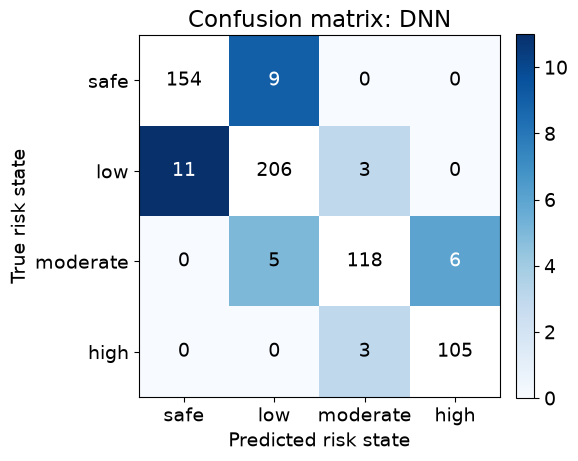

In [111]:
hidden_values     = [r[0] for r in results_mlp]
alpha_values      = np.array([r[1] for r in results_mlp])
lr_values         = np.array([r[2] for r in results_mlp])
activation_values = np.array([r[3] for r in results_mlp])
batch_values      = np.array([r[4] for r in results_mlp])

acc    = np.array([r[5] for r in results_mlp])
prec   = np.array([r[6] for r in results_mlp])
recall = np.array([r[7] for r in results_mlp])
f1     = np.array([r[8] for r in results_mlp])
conf   = [r[9] for r in results_mlp]
custum = np.array([r[10] for r in results_mlp])
n_iter = np.array([r[11] for r in results_mlp])

# Find best combination based on custom metric (lower is better)
valid = np.where(np.isfinite(custum))[0]

if len(valid) == 0:
    print("No models with a finite custom metric.")
else:
    best_idx = valid[np.argmin(custum[valid])]

    print("Model: MLP Classifier")
    print("Number of combinations:", len(acc))
    print("Best custom metric value:", custum[best_idx])
    print("Best hidden_layer_sizes:", hidden_values[best_idx])
    print("Best alpha:", alpha_values[best_idx])
    print("Best learning_rate_init:", lr_values[best_idx])
    print("Best activation:", activation_values[best_idx])
    print("Best batch_size:", batch_values[best_idx])
    print("Best accuracy:", acc[best_idx])
    print("Best F1:", f1[best_idx])
    print("Training iterations:", n_iter[best_idx])
    print("Best confusion matrix:")
    print(conf[best_idx])

plot_confusion(conf[best_idx], "DNN")